[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


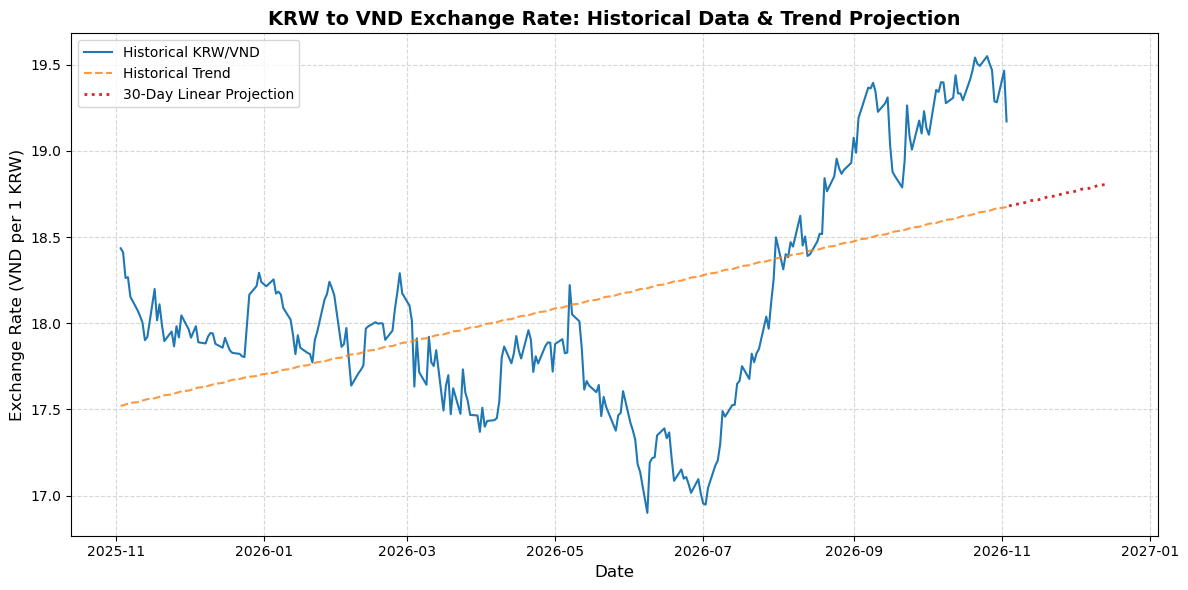

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

# 1. Download USD/KRW (KRW=X) and USD/VND (VND=X)
print("Downloading exchange rate data...")
krw_data = yf.download("KRW=X", period="1y", interval="1d", auto_adjust=True)
vnd_data = yf.download("VND=X", period="1y", interval="1d", auto_adjust=True)


# Helper function to safely extract Close prices
def get_close(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"].iloc[:, 0]
  return df["Close"]


krw_close = get_close(krw_data)
vnd_close = get_close(vnd_data)

# Combine and align dates, dropping any missing values
df = pd.DataFrame({"KRW": krw_close, "VND": vnd_close}).dropna()

# Calculate KRW to VND cross rate: (USD/VND) / (USD/KRW)
prices = df["VND"] / df["KRW"]

# 2. Create a simple linear regression projection for the next 30 days
x = np.arange(len(prices))
y = prices.values

# Fit a degree 1 polynomial (linear trendline: y = mx + c)
coeffs = np.polyfit(x, y, 1)
trend_line_fn = np.poly1d(coeffs)

# Generate future days for projection (next 30 business days)
future_days = 30
x_future = np.arange(len(prices), len(prices) + future_days)
future_dates = pd.date_range(
    start=prices.index[-1] + pd.Timedelta(days=1), periods=future_days, freq="B"
)
future_prices = trend_line_fn(x_future)

# 3. Plotting the historical data and future projection
plt.figure(figsize=(12, 6))

plt.plot(
    prices.index,
    prices,
    label="Historical KRW/VND",
    color="#1f77b4",
    linewidth=1.5,
)
plt.plot(
    prices.index,
    trend_line_fn(x),
    label="Historical Trend",
    color="#ff7f0e",
    linestyle="--",
    alpha=0.8,
)
plt.plot(
    future_dates,
    future_prices,
    label="30-Day Linear Projection",
    color="#d62728",
    linestyle=":",
    linewidth=2,
)

# Chart styling
plt.title(
    "KRW to VND Exchange Rate: Historical Data & Trend Projection",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Exchange Rate (VND per 1 KRW)", fontsize=12)
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.show()

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


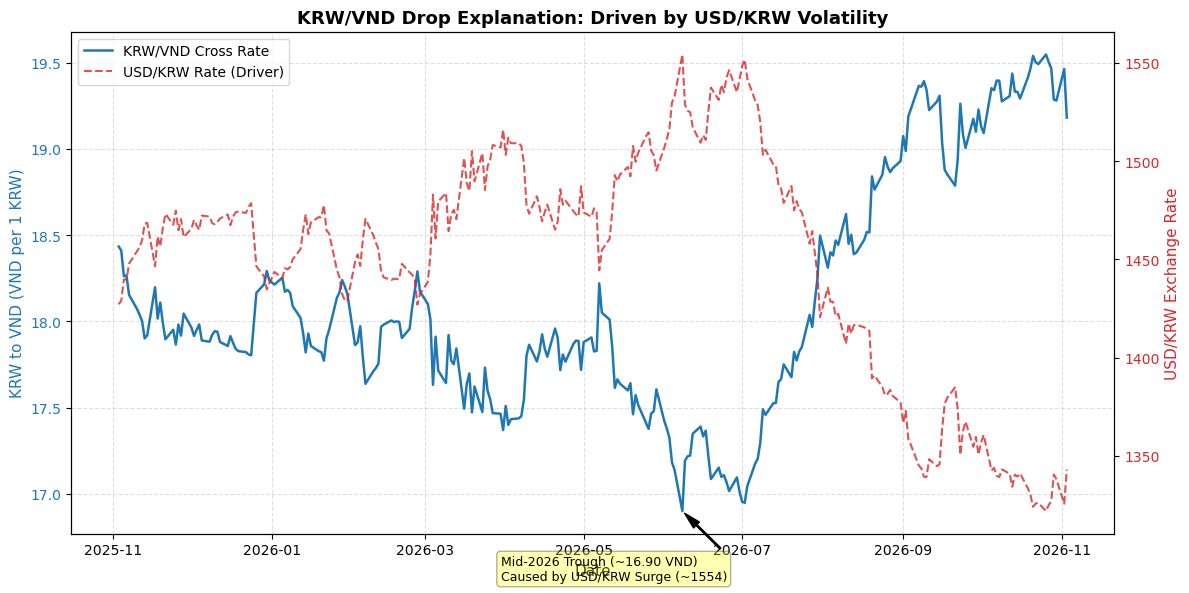

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

# 1. Fetch raw underlying data feeds
usd_krw = yf.download("KRW=X", period="1y", interval="1d", auto_adjust=True)
usd_vnd = yf.download("VND=X", period="1y", interval="1d", auto_adjust=True)


def extract_close(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"].iloc[:, 0]
  return df["Close"]


krw = extract_close(usd_krw)
vnd = extract_close(usd_vnd)

# Align datasets and construct cross-rate
df = pd.DataFrame({"USD_KRW": krw, "USD_VND": vnd}).dropna()
df["KRW_VND"] = df["USD_VND"] / df["USD_KRW"]

# 2. Build Multi-Series Explanatory Visualization
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Primary Axis: KRW/VND Cross-Rate
color_krw_vnd = "#1f77b4"
ax1.set_xlabel("Date", fontsize=11)
ax1.set_ylabel("KRW to VND (VND per 1 KRW)", color=color_krw_vnd, fontsize=11)
line1 = ax1.plot(
    df.index,
    df["KRW_VND"],
    color=color_krw_vnd,
    linewidth=1.8,
    label="KRW/VND Cross Rate",
)
ax1.tick_params(axis="y", labelcolor=color_krw_vnd)

# Plot Secondary Axis: USD/KRW Exchange Rate (Inverted to visually map correlation)
ax2 = ax1.twinx()
color_usd_krw = "#d62728"
ax2.set_ylabel("USD/KRW Exchange Rate", color=color_usd_krw, fontsize=11)
line2 = ax2.plot(
    df.index,
    df["USD_KRW"],
    color=color_usd_krw,
    linestyle="--",
    linewidth=1.5,
    alpha=0.8,
    label="USD/KRW Rate (Driver)",
)
ax2.tick_params(axis="y", labelcolor=color_usd_krw)

# Annotate the Mid-2026 Trough / Spike
trough_date = df["KRW_VND"].idxmin()
trough_val = df["KRW_VND"].min()
usd_peak = df.loc[trough_date, "USD_KRW"]

ax1.annotate(
    f"Mid-2026 Trough (~{trough_val:.2f} VND)\nCaused by USD/KRW Surge (~{usd_peak:.0f})",
    xy=(trough_date, trough_val),
    xytext=(
        trough_date - pd.Timedelta(days=70),
        trough_val - 0.4,
    ),  # Position text to the left of the trough
    arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=6),
    fontsize=9,
    bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.3),
)

# Formatting
plt.title(
    "KRW/VND Drop Explanation: Driven by USD/KRW Volatility",
    fontsize=13,
    fontweight="bold",
)
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper left")
ax1.grid(True, linestyle="--", alpha=0.4)

fig.tight_layout()
plt.show()

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


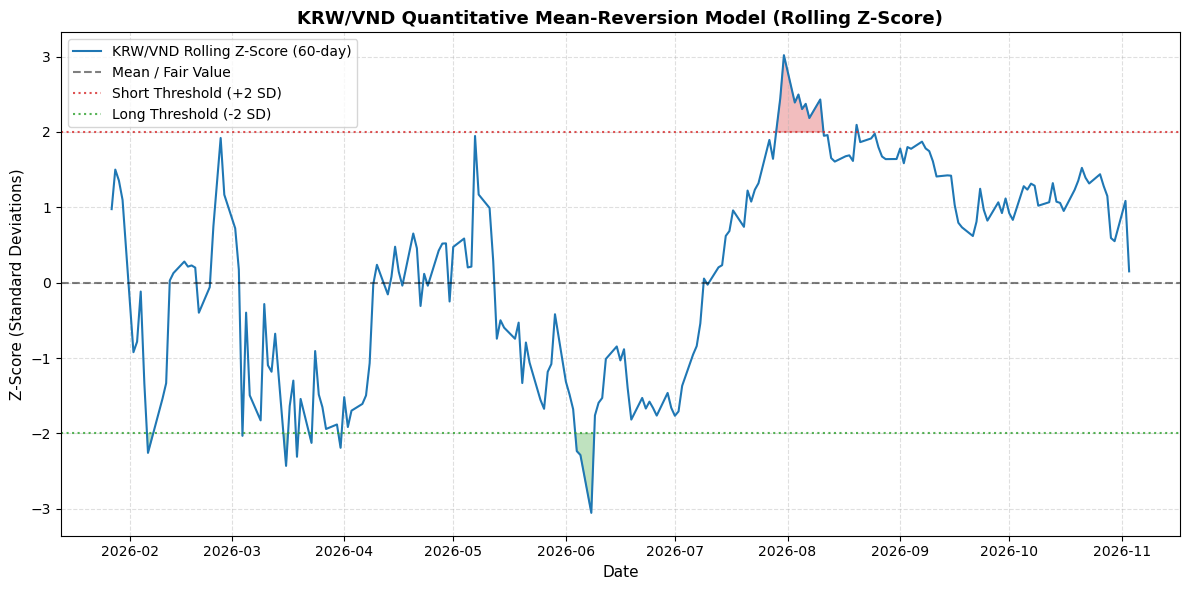

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

# 1. Download underlying series
print("Downloading exchange rate data...")
usd_krw = yf.download("KRW=X", period="1y", interval="1d", auto_adjust=True)
usd_vnd = yf.download("VND=X", period="1y", interval="1d", auto_adjust=True)


def extract_close(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"].iloc[:, 0]
  return df["Close"]


df = pd.DataFrame(
    {"USD_KRW": extract_close(usd_krw), "USD_VND": extract_close(usd_vnd)}
).dropna()

# 2. Calculate KRW/VND Cross-Rate
df["KRW_VND"] = df["USD_VND"] / df["USD_KRW"]

# 3. Compute Rolling Z-Score (using a 60-day rolling window)
window = 60
rolling_mean = df["KRW_VND"].rolling(window=window).mean()
rolling_std = df["KRW_VND"].rolling(window=window).std()

df["Z_Score"] = (df["KRW_VND"] - rolling_mean) / rolling_std
df = df.dropna()

# 4. Plotting the Rigorous Statistical Trading Domain
plt.figure(figsize=(12, 6))

plt.plot(
    df.index,
    df["Z_Score"],
    label="KRW/VND Rolling Z-Score (60-day)",
    color="#1f77b4",
    linewidth=1.5,
)

# Statistical Thresholds for Trading Signals
plt.axhline(
    0, color="black", linestyle="--", alpha=0.5, label="Mean / Fair Value"
)
plt.axhline(
    2.0, color="#d62728", linestyle=":", alpha=0.8, label="Short Threshold (+2 SD)"
)
plt.axhline(
    -2.0, color="#2ca02c", linestyle=":", alpha=0.8, label="Long Threshold (-2 SD)"
)

# Highlight extreme deviation zones accurately where thresholds are breached
plt.fill_between(
    df.index,
    df["Z_Score"],
    2.0,
    where=(df["Z_Score"] >= 2.0),
    color="#d62728",
    alpha=0.3,
    interpolate=True,
)
plt.fill_between(
    df.index,
    df["Z_Score"],
    -2.0,
    where=(df["Z_Score"] <= -2.0),
    color="#2ca02c",
    alpha=0.3,
    interpolate=True,
)

# Chart Formatting
plt.title(
    "KRW/VND Quantitative Mean-Reversion Model (Rolling Z-Score)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Date", fontsize=11)
plt.ylabel("Z-Score (Standard Deviations)", fontsize=11)
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

plt.show()